In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, gc
import random
import traceback

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import tqdm
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

import data_loaders
from data_loaders import CommitedDataset, JaggedCommittedDataset, commit_dataset_jagged
from dl_trainer import Trainer, sequence_collate, create_sequence_collator
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommenderV2, ConcatInteractionHistoryRepresentationWithUserEmbedInitialization
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, norm_dot_product_based_relavance_calculation

In [3]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [4]:
try:
    ds_train_v2 = CommitedDataset('KuaiRecData_smaller', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [5]:
try:
    d_embed = 128
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=512, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=512, d_embed=d_embed, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [7]:
try:
    embed_trainer = Trainer(model=model, train_dataloader=DataLoader(ds_train_v2, batch_size=8192))
except:
    traceback.print_exc()

In [73]:
try:
    # embed_trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
    embed_trainer.load_checkpoint('model_id_trained_embedder_v3_128.pt', save_backup=False)
except:
    traceback.print_exc()

In [74]:
try:
    uid = [3434, 1281, 5008]
    uft = data_model.get_user_features(uid)
    uem, ubs = user_model.embed(uid, uft)
    print(uem[0, :3], ubs[0])
    user_model.update_embeds(uid, uft, 100 * np.ones_like(uem), 10 * np.ones_like(ubs))
    uem, ubs = user_model.embed(uid, uft)
    print(uem[0, :3], ubs[0])
    embed_trainer.load_checkpoint('model_id_trained_embedder_v3_128.pt', save_backup=False)
except:
    traceback.print_exc()

[-467.55847  807.8121   833.5204 ] -0.006599553
[ 99.99997 100.      100.     ] 10.0


In [8]:
try:
    history_model = ConcatInteractionHistoryRepresentationWithUserEmbedInitialization(d_embed, 512)
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = False
    recommender = ThreeTowerRecommenderV2(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [9]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_train_v2))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0)
        hft = torch.cat([nif, nif, nif], dim=0)
        hid, hft = torch.stack([hid, hid], dim=0), torch.stack([hft, hft], dim=0)
        msk = torch.tensor([3, 3])
        les = torch.tensor([3])
        hcl = torch.ones((2, 3))
        hcl[:, 1] = 0

        pem, (_, pbs) = recommender(uid, uft, hid, hft, hcl, msk, les)

        uem, ubs = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)

        print((uem * pie).mean(dim=1) + ubs + pib)
        print((uem * nie).mean(dim=1) + ubs + nib)
        print((uem * pem[:1]).mean(dim=1) + ubs + pbs)
except:
    traceback.print_exc()

tensor([-16907.9355])
tensor([-26263.6699])
tensor([3.5238])


# IIITCPI 2

In [ ]:
class PretrainerDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.history_size = history_zise
        self.length = length

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        his = self.data_model.ratings['item_id'].sample(random.randint(5, self.history_size)).to_numpy()
        hfs = self.data_model.get_item_features(his)
        with torch.no_grad():
            hem, hbs = item_model(torch.tensor(his), torch.tensor(hfs))
            hem, hbs = hem.numpy(), hbs.numpy()
        hcs = np.random.randint(0, 2, (len(his),))

        eff_hem, eff_hbs = hem[hcs == 1], hbs[hcs == 1]
        if len(eff_hem) == 0: return self.__getitem__(idx)
        wei = np.linspace(0, 2 / len(eff_hem), len(eff_hem), dtype=np.float32)
        eff_hem, eff_hbs = (eff_hem * wei[:, None]).sum(0), (eff_hbs * wei).sum(0)

        return (hem, hbs, hcs.astype(np.float32)), (eff_hem, eff_hbs)


try:
    pds = PretrainerDataset(data_model, 10, length=2048)
    for _, sample in zip(range(1), pds):
        print("sample", [y.shape for x in sample for y in x])
except:
    traceback.print_exc()

In [ ]:
try:
    abc = DataLoader(pds, batch_size=2, collate_fn=sequence_collate)
    for _, sample in zip(range(1), abc):
        print("mi", sample[0][0].shape)
        print("mi", sample[0][1].shape)
        print("mi", sample[0][2].shape)
        print("mi", sample[0][3].shape)
        print("gt", sample[1][0].shape)
        print("gt", sample[1][1].shape)
except:
    traceback.print_exc()

In [ ]:
def pre_his_loss(preds, truth):
    hem, hbs = preds
    eff_hem, eff_hbs = truth

    loss = F.mse_loss(hem, eff_hem)
    if hbs is not None:
        loss += F.mse_loss(hbs, eff_hbs.unsqueeze(-1))

    return loss


def running_average(arr, window=10):
    return np.convolve(arr, np.ones(window), 'valid') / window


try:
    history_training_loss = locals().get('history_training_loss', None)
    history_trainer = Trainer(
        model=recommender.history_model,
        train_dataloader=DataLoader(pds, batch_size=4, collate_fn=sequence_collate),
        epochs=10,
        dataset_fraction=10,
        criterion=pre_his_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.000001),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
    )
    history_training_loss = history_trainer.loss
    history_trainer.load_model("model_history_embeds_v3.pt")
except:
    traceback.print_exc()

In [ ]:
try:
    history_trainer.epochs = 10
    # history_trainer.learning_rate(0.003)
except:
    traceback.print_exc()

In [ ]:
try:
    history_trainer.train()

    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(history_trainer.loss['train'])
    axs[1].plot(history_trainer.loss['train.batch'])
    axs[1].plot(running_average(history_trainer.loss['train.batch'], 20))
except:
    traceback.print_exc()

In [ ]:
try:
    # history_trainer.loss['train.batch'] = history_trainer.loss['train.batch'][150:]
    print(len(history_trainer.loss['train.batch']))
except:
    traceback.print_exc()

In [ ]:
try:
    history_trainer.save_model("history_embeds_v3")
except:
    traceback.print_exc()

In [ ]:
try:
    print(data_model.ratings['item_id'].sample(1).values[0])
    print(data_model.ratings.iloc[0]['user_id'].astype(np.int64))
except:
    traceback.print_exc()

# HERE

In [10]:
try:
    index = faiss.IndexFlatIP(d_embed)
    idxToIid = {}
    with torch.no_grad():
        for idx, iid in enumerate(data_model.ratings['item_id'].unique()):
            item_model.eval()
            iem, *_ = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            index.add(iem.numpy())
            idxToIid[idx] = iid
except:
    traceback.print_exc()

In [11]:
try:
    uid = random.randint(0, 1000)
    uft = data_model.get_user_features(uid)
    with torch.no_grad():
        user_model.eval()
        uem, ubs = user_model(
            torch.tensor([uid], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
        uem, ubs = uem.numpy(), ubs.numpy().squeeze()
        scores, indices = index.search(uem, 1)
        print(indices)
        iid = idxToIid[int(indices.squeeze())]
        ift = data_model.get_item_features(iid)
        item_model.eval()
        iem, *_ = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
        iem = iem.numpy()
        print((uem * iem).sum())
except:
    traceback.print_exc()

[[1407]]
9.39903e+06


In [12]:
# def norm_press_preference(preference):
#     print("Hello", preference.shape)
#     with torch.no_grad():
#         return user_model.embedder[2](torch.tensor(preference)).numpy()


try:
    with torch.no_grad():
        uids = data_model.ratings['user_id'].unique()
        user_model.eval()
        uem, _ = user_model(
            torch.tensor(uids, dtype=torch.int64),
            torch.tensor(data_model.get_user_features(uids), dtype=torch.float32))
        print(uem.shape)
    user_embed_mean = uem.mean(dim=1).mean().numpy()
    user_embed_std = uem.std(dim=1).mean().numpy()
    print("Mean", user_embed_mean, "Std", user_embed_std)


    def norm_press_preference(preference):
        preference = (preference - preference.mean()) / preference.std()
        return preference * user_embed_std + user_embed_mean

except:
    traceback.print_exc()

torch.Size([1411, 128])
Mean 25.018114 Std 463.4131


In [13]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def preference_function(pref, iem, ibs, ubs):
    # TODO: What would be a good way to convert it to probabilities?
    #  The raw preference calculated by the dot product ranges in -.6 to +.6 with an std of only 0.2
    #  For the time being I am using a simple hack
    print("pref", pref.min(), pref.max(), pref.std())
    print("iem", iem.min(), iem.max(), iem.std())
    print("SHAPE", pref.shape, iem.shape, (pref * iem).shape, ((pref * iem).sum()).shape)
    print("DOT", (pref * iem).min(), (pref * iem).max(), (pref * iem).std())
    dot = (pref * iem).sum()
    print("dotsum", dot.min(), dot.max(), dot.std())
    raw_relevance = (pref * iem).sum() + ubs + ibs.squeeze()
    print("raw_relevance", raw_relevance.std(), raw_relevance.min(), raw_relevance.max(), raw_relevance)
    return sigmoid(raw_relevance / 0.62 * 6)


class UserModelDataset_OLD(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

            self.users[uid] = DynamicPreferenceUserModel(
                preference=uem,
                preference_volatility=0.001854,
                relevance_calculator=lambda pref, iem, ibs, ubs=ubs: preference_function(pref, iem, ibs, ubs),
            )
        self.flip = True

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)

        subset = data_model.ratings[data_model.ratings['user_id'] == user_id]

        user = self.users[user_id]
        user.reset()

        hist_id = []
        hist_feats = []
        hist_clk = []

        for iid in subset.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                # print(user._relevance)
                hist_clk.append(clk)
                # print(iem.std(), user.preference.std())

        if self.flip:
            # print("flip T", end=' ')
            subset = subset[subset['rating'] > 0.75]
        else:
            # print("flip F", end=' ')
            subset = subset[subset['rating'] <= 0.75]
        for iid in subset.sample(1)['item_id']:
            ift = self.data_model.get_item_features(iid)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()
                clk = np.int64(user.react(None, None, iem, ibs))
                print("Rel", user._relevance)

        self.flip = not self.flip

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    iem.flatten(),
                    ibs,
                    clk,
                ))


def random_perpendicular(v):
    shape = v.shape
    v = v.flatten()
    v = np.asarray(v)
    rand = np.random.randn(*v.shape)  # random vector
    proj = np.dot(rand, v) / np.dot(v, v) * v  # projection of rand onto v
    perp = rand - proj  # subtract projection → perpendicular component
    return perp.reshape(shape)


class UserModelDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.base_seed = random.randint(0, 1000000)

        self.users = {}

        with torch.no_grad():
            for uid in self.ratings['user_id'].unique():
                user_model.eval()
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

                self.users[int(uid)] = DynamicPreferenceUserModel(
                    preference=uem,
                    preference_bias=ubs,
                    preference_volatility=0.001854,
                    relevance_calculator=norm_dot_product_based_relavance_calculation,
                    preference_update_manager=norm_press_preference,
                )

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        random.seed(self.base_seed + idx)
        np.random.seed(self.base_seed + idx)
        # This line only exists since we want longer datasets, not matching up with the unique user counts
        # Otherwise, we could have used the idx on a separate unique user to rating map
        idx = random.randint(0, len(self.ratings) - 1)

        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)
        user = self.users[int(user_id)]
        user.reset()

        # print("user_id", user_id)

        hist_data = []

        # We need some positive samples, some negative... How do we proceed?

        with torch.no_grad():
            for i in range(random.randint(5, self.history_size)):
                if random.random() < 0.5:  # Lol what!? 80%!?!?!
                    iid = int(self.ratings['item_id'].iloc[np.random.randint(0, len(self.ratings))])
                    # p = random_perpendicular(user.preference)
                    # iid = int(index.search(p, 1)[1].flatten()[0].squeeze())
                    # iid = int(index.search(-user.preference, 1)[1].flatten()[0].squeeze())
                    # iid = int(index.search(p, 10)[1].flatten()[random.randint(0, 9)].squeeze())
                    # iid = idxToIid[iid]
                else:
                    iid = int(index.search(user.preference, 10)[1].flatten()[random.randint(0, 9)].squeeze())
                    iid = idxToIid[iid]

                # print("iid", iid)

                ift = self.data_model.get_item_features(iid)
                item_model.eval()
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()

                # print("PEF", user.preference)
                # print("REL", user.preference.std(), user.preference.mean())

                # print("REL", user._get_relevance(None, None, iem, ibs))
                click = user.react(None, None, iem, ibs)
                # print("CLK", click)
                hist_data.append((iid, ift, click, iem, ibs))

        hist_id, hist_feats, hist_clk, _, _ = zip(*hist_data[:-1])

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    hist_data[-1][3].flatten(),
                    hist_data[-1][4],
                    np.float32(hist_data[-1][2]),
                ))


try:
    umd = UserModelDataset(data_model, 20, length=1024)
    for sample in umd:
        print(len(sample), len(sample[0]), len(sample[1]))
        print([x.shape for x in sample[0]])
        print([y.shape for y in sample[1]])
        break
except:
    traceback.print_exc()

2 5 3
[(), (1582,), (9,), (9, 429), (9,)]
[(128,), (1,), ()]


In [14]:
try:
    # (uid, uft, hids, hfts, hclk), (iem, ibs, clk) = umd[0]
    pref = umd.users[723].preference
    iid = data_model.item_features.sample(1).index.to_numpy()[0]
    # iid = int(umd.ratings['item_id'].iloc[np.random.randint(0, len(umd.ratings))])
    with torch.no_grad():
        ift = umd.data_model.get_item_features(iid)
        item_model.eval()
        iem, ibs = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(ift[None, :], dtype=torch.float32))
        iem, ibs = iem.numpy(), ibs.numpy()
        print((pref * iem).sum())
except:
    traceback.print_exc()

1.0136961e+06


In [15]:
try:
    # (uid, uft, hids, hfts, hclk), (iem, ibs, clk) = umd[0]
    pref = umd.users[723].preference
    print(pref.mean(), pref.std(), pref.min(), pref.max(), np.linalg.norm(pref))
    pref = umd.users[5299].preference
    print(pref.mean(), pref.std(), pref.min(), pref.max(), np.linalg.norm(pref))
except:
    traceback.print_exc()

28.738739 463.99652 -902.61536 641.14026 5259.581
26.616055 507.31354 -1229.2063 946.7548 5747.491


### We want a balanced number of clock and non click predictions

Ideally `np.mean(clks) == 0.5`

In [16]:
try:
    pos = []
    neg = []
    clks = []
    # for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(256)), umd):
        for cc in hclk.squeeze():
            if cc: pos.append(clk)
            else: neg.append(clk)
        clks.append(clk)
    print("Total POS in History", len(pos))
    print("Total NEG in History", len(neg))
    print("POS/NEG in History    (Expected 1.0) ", len(pos) / len(neg))
    print("Average Y Interaction (Expected 0.5) ", np.mean(clks))

    # Sel p 0.8    gives 5   and 0.97
    # Sel p 0.2    gives 8   and 0.98
    # Sel p 0.99   gives 4.8 and 0.96
    # Sel p 0.9999 gives 4.7 and 0.95
except:
    traceback.print_exc()

100%|██████████| 256/256 [00:01<00:00, 155.34it/s]

Total POS in History 1454
Total NEG in History 1427
POS/NEG in History    (Expected 1.0)  1.0189208128941836
Average Y Interaction (Expected 0.5)  0.52734375


### Checking if the data even has a bias towards positive predictions

Ideally `len(pos) / len(neg) == 1`

In [17]:
try:
    subset = data_model.ratings[data_model.ratings['user_id'] == 1520]
    uft = data_model.get_user_features(1520)
    with torch.no_grad():
        uem, ubs = user_model(
            torch.tensor([1520], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
    pos, neg = [], []
    for iid in subset[subset['rating'] < 0.8]['item_id']:
        ift = data_model.get_item_features(iid)
        with torch.no_grad():
            item_model.eval()
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(ift[None, :], dtype=torch.float32))
            rel = float((iem * uem).sum() + ubs + ibs)
            rel = rel / 2 + 0.5
            if random.random() < rel: pos.append(1)
            else: neg.append(1)

    print(len(pos) / len(neg))
    # print(np.mean(pos), np.mean(neg))
except:
    traceback.print_exc()

0.3288135593220339


In [18]:
try:
    if False:
        commit_dataset_jagged(umd, 'UserModelDataset', path=os.path.join('..', 'temp', 'commited_datasets'))
    if True:
        umd_v2 = JaggedCommittedDataset('UserModelDataset', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [19]:
try:
    ids = []
    for sample in umd_v2:
        ids.append(sample[0][2].min())
        # print(sample[0][2].shape)
        # break
    print(np.min(ids))
except:
    traceback.print_exc()

103


In [156]:
def bce_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    # print("uem, (ubs, hbs)", uem.shape, ubs.shape, hbs.shape)
    # print("iem, ibs, clk", iem.shape, ibs.shape, clk.shape)
    # print("iem stats:", iem.min().item(), iem.max().item(), iem.abs().mean().item())
    # print("uem stats:", uem.min().item(), uem.max().item(), uem.abs().mean().item())
    if ubs is None: ubs = 0
    # rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs.squeeze() + hbs.squeeze() + ibs.squeeze()) / 0.62 * 6)
    uem = F.normalize(uem, dim=1)
    iem = F.normalize(iem, dim=1)
    logit = (uem * iem).sum(dim=1) + ubs.squeeze() + ibs.squeeze() + (0 if hbs is None else hbs.squeeze())
    # print(f"logit mean={logit.mean():.3f}, std={logit.std():.3f}")
    # print("logit", logit.shape, "clk", clk.shape)
    return F.binary_cross_entropy_with_logits(logit, clk.squeeze(-1))


def mse_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    if ubs is None: ubs = 0
    # TODO: Rfere to the same comment made in user model regarding probability conversion to understand `/ 0.62 * 6`
    rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs + ibs) / 0.62 * 6)
    # print(rel)
    return F.mse_loss(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, hcl = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(len(x) for x in hid)
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    hcl = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hcl])
    iem, ibs, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    iem = torch.tensor(iem)
    ibs = torch.tensor(ibs).flatten()
    clk = torch.tensor(clk).float()
    return (uid, uft, hid, hft, hcl, mask), (iem, ibs, clk)

In [21]:
loss = None

In [22]:
try:
    trainer = Trainer(
        model=recommender,
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=collate_fn),
        train_dataloader=DataLoader(umd_v2, batch_size=128, collate_fn=create_sequence_collator(
            (False, False, True, True, True)
        )),
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=sequence_collate),
        epochs=5,
        criterion=bce_loss,
        # criterion=mse_loss,
        # optimizer=lambda x: torch.optim.Adam(x, lr=0.001),
        optimizer=lambda x: torch.optim.AdamW(x, lr=0.01),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [248]:
try:
    pass
    # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
    # trainer.load_checkpoint(save_backup=False)
    # trainer.load_model('model_recommender_v6.pt')
    trainer.device = 'cuda'
    trainer.criterion = bce_loss

    trainer.epochs = 500
    # trainer.dataset_fraction = None
    trainer.learning_rate(0.000001)
    # trainer.train_dataloader = DataLoader(umd_v2, batch_size=128 * 8, collate_fn=create_sequence_collator(
    #     (False, False, True, True, True)
    # ))
    # trainer.optimizer = torch.optim.AdamW([
    #     {'params': recommender.history_model.parameters(), 'lr': 0.001},
    #     {'params': recommender.alpha.parameters(), 'lr': 0.00001},
    # ], lr=0.0)

    # print(recommender.history_model)
except:
    traceback.print_exc()

In [249]:
try:
    trainer.train()
    # TODO: Try weight based model for history embeds instead of RNN
    # 2 epochs, battery, 61 sec
    # 2 epochs, charge, same
except:
    traceback.print_exc()

Epoch:  1/500    Train Loss: 0.69    TTS: 0.42
Epoch:  2/500    Train Loss: 0.69    TTS: 0.56
Epoch:  3/500    Train Loss: 0.69    TTS: 0.69
Epoch:  4/500    Train Loss: 0.69    TTS: 0.83
Epoch:  5/500    Train Loss: 0.69    TTS: 0.98
Epoch:  6/500    Train Loss: 0.69    TTS: 1.10
Epoch:  7/500    Train Loss: 0.69    TTS: 1.25
Epoch:  8/500    Train Loss: 0.69    TTS: 1.39
Epoch:  9/500    Train Loss: 0.69    TTS: 1.53
Epoch: 10/500    Train Loss: 0.69    TTS: 1.69
Epoch: 11/500    Train Loss: 0.69    TTS: 1.83
Epoch: 12/500    Train Loss: 0.69    TTS: 1.98
Epoch: 13/500    Train Loss: 0.69    TTS: 2.23
Epoch: 14/500    Train Loss: 0.69    TTS: 2.38
Epoch: 15/500    Train Loss: 0.69    TTS: 2.55
Epoch: 16/500    Train Loss: 0.69    TTS: 2.69
Epoch: 17/500    Train Loss: 0.69    TTS: 2.83
Epoch: 18/500    Train Loss: 0.69    TTS: 2.98
Epoch: 19/500    Train Loss: 0.69    TTS: 3.13
Epoch: 20/500    Train Loss: 0.69    TTS: 3.27
Epoch: 21/500    Train Loss: 0.69    TTS: 3.42
Epoch: 22/500

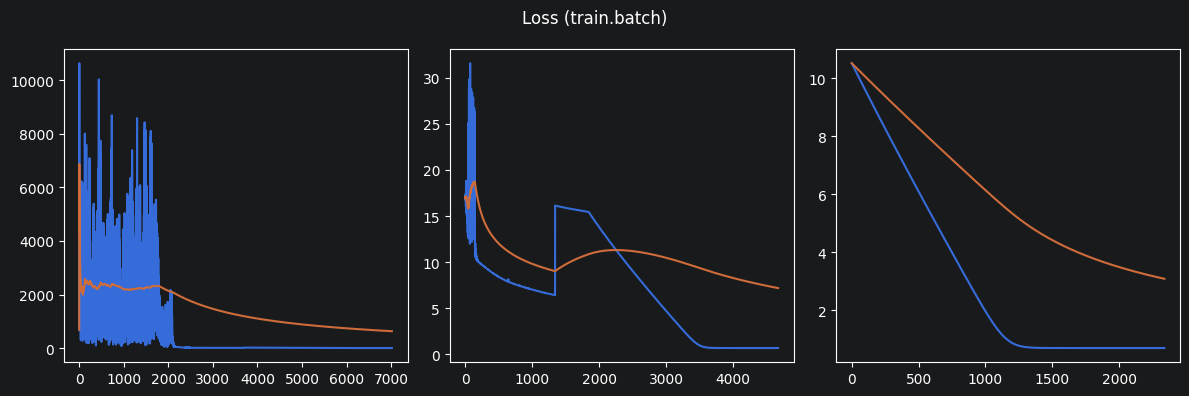

In [250]:
try:
    trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

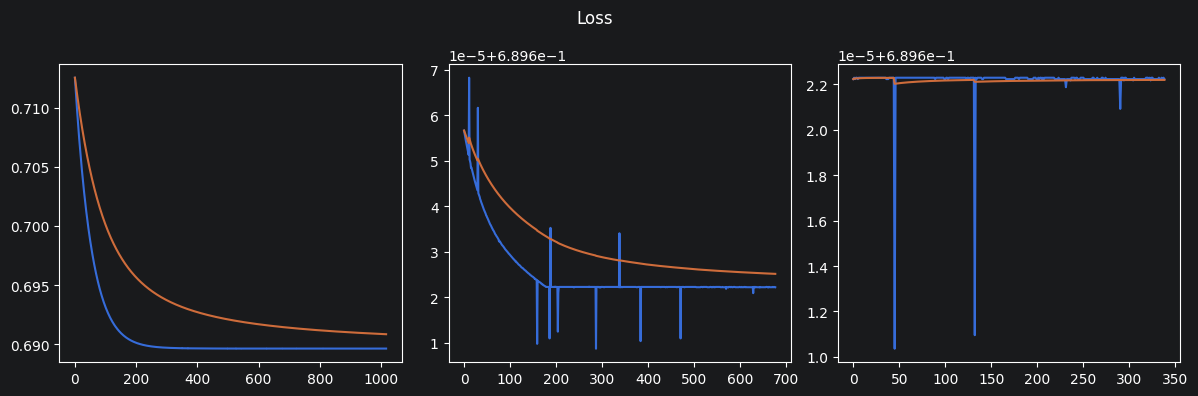

In [251]:
try:
    trainer.plot_loss(trainer.loss['train.batch'][6000::])
except:
    traceback.print_exc()

In [252]:
try:
    # trainer.loss['train.batch'] = trainer.loss['train.batch'][-25:]
    print(len(trainer.loss['train.batch']))
except:
    traceback.print_exc()

7017


In [253]:
try:
    trainer.save_model("recommender_v6")
except:
    traceback.print_exc()

In [254]:
try:
    with torch.no_grad():
        (uid, uft, hid, hft, hcl, msk, lns), (iem, ibs, clk) = next(iter(DataLoader(
            umd_v2, batch_size=1,
            shuffle=True,
            collate_fn=create_sequence_collator((False, False, True, True, True)))))

        print(uid.shape, uft.shape, hid.shape, hft.shape, hcl.shape, msk.shape, lns.shape)
        uid, uft, hid, hft, hcl, msk, lns = uid.to('cuda'), uft.to('cuda'), hid.to('cuda'), hft.to('cuda'), hcl.to('cuda'), msk.to('cuda'), lns.to('cuda')
        iem, ibs, clk = iem.to('cuda'), ibs.to('cuda'), clk.to('cuda')

        uem, ubs = user_model(uid, uft)
        # F.normalize(, dim=1)
        print("Without History (w/o b)", (F.normalize(uem, dim=1) * F.normalize(iem, dim=1)).sum())
        print("Without History (w/  b)", (F.normalize(uem, dim=1) * F.normalize(iem, dim=1)).sum() + ubs + ibs)

        pref = torch.tensor(umd.users[uid.item()].preference).to('cuda')
        print("Actual Preference (w/o b)", (F.normalize(pref, dim=1) * F.normalize(iem, dim=1)).sum())
        print("Actual Preference (w/  b)", (F.normalize(pref, dim=1) * F.normalize(iem, dim=1)).sum() + ubs + ibs)
        print("Click", clk)

        pref = torch.tensor(umd.users[uid.item()]._state_vector['preference']).to('cuda')
        print("Original Preference (w/o b)", (F.normalize(pref, dim=1) * F.normalize(iem, dim=1)).sum())
        print("Original Preference (w/  b)", (F.normalize(pref, dim=1) * F.normalize(iem, dim=1)).sum() + ubs + ibs)

        alpha = recommender.alpha(uem)
        print('history weight', 1 - alpha)

        uem2, (ubs2, hbs) = recommender(uid, uft, hid, hft, hcl, msk, lns)
        print("With History (w/o b)", (F.normalize(uem2, dim=1) * F.normalize(iem, dim=1)).sum())
        print("With History (w/  b)", (F.normalize(uem2, dim=1) * F.normalize(iem, dim=1)).sum() + ubs2 + ibs + hbs)
        # print("With History", (uem2 * iem).sum() + ubs2 + ibs + hbs)

        print("bce_loss", bce_loss((uem2, (ubs2, hbs)), (iem, ibs, clk)))

except:
    traceback.print_exc()

torch.Size([1, 1]) torch.Size([1, 1582]) torch.Size([1, 11]) torch.Size([1, 11, 429]) torch.Size([1, 11]) torch.Size([1, 11]) torch.Size([1])
Without History (w/o b) tensor(0.1478, device='cuda:0')
Without History (w/  b) tensor([[0.1470]], device='cuda:0')
Actual Preference (w/o b) tensor(0.1518, device='cuda:0')
Actual Preference (w/  b) tensor([[0.1510]], device='cuda:0')
Click tensor([[1.]], device='cuda:0')
Original Preference (w/o b) tensor(0.1518, device='cuda:0')
Original Preference (w/  b) tensor([[0.1510]], device='cuda:0')
history weight tensor([[1.]], device='cuda:0')
With History (w/o b) tensor(0.0256, device='cuda:0')
With History (w/  b) tensor([[0.0267]], device='cuda:0')
bce_loss tensor(0.6799, device='cuda:0')


In [255]:
try:
    with torch.no_grad():
        res = []
        for _ in tqdm.tqdm(range(1000)):
            (uid, uft, hid, hft, hcl, msk, lns), (iem, ibs, clk) = next(iter(DataLoader(
                umd_v2, batch_size=1,
                shuffle=True,
                collate_fn=create_sequence_collator((False, False, True, True, True)))))
            uid, uft, hid, hft, hcl, msk, lns = uid.to('cuda'), uft.to('cuda'), hid.to('cuda'), hft.to('cuda'), hcl.to('cuda'), msk.to('cuda'), lns.to('cuda')
            iem, ibs, clk = iem.to('cuda'), ibs.to('cuda'), clk.to('cuda')

            uem, ubs = user_model(uid, uft)
            pref = torch.tensor(umd.users[uid.item()].preference).to('cuda')
            pref = torch.tensor(umd.users[uid.item()]._state_vector['preference']).to('cuda')
            alpha = recommender.alpha(uem)
            uem2, (ubs2, hbs) = recommender(uid, uft, hid, hft, hcl, msk, lns)
            res.append((clk.item(), ((F.normalize(uem2, dim=1) * F.normalize(iem, dim=1)).sum() + ubs2 + ibs + hbs).item()))

        c = 0
        for r in res:
            if r[0] == 1 and r[1] >= 0: c += 1
            if r[0] == 0 and r[1] < 0: c += 1
        print(c)
        print(c / len(res))
except:
    traceback.print_exc()

100%|██████████| 1000/1000 [00:04<00:00, 235.79it/s]

559
0.559


In [ ]:
try:
    # print(uem2.sum().backward(retain_graph=True))
    print(list(history_model.parameters())[0].grad)
    # print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][5:]
except:
    traceback.print_exc()

In [256]:
# TODO: Add a Linear after the uem iem to possibly manage the offset bias which was not learnt
# TODO: Also maybe try using more concrete click behaviour
#  Instead of click = rand() < relevance
#  Try        click = relevance > 0
#  Or even    click = rand() < relevance ** 0.5